# led_thermometer — схемы

Источник всех картинок проекта. Каждая ячейка рисует одну схему, сохраняет её в `docs/diagrams/<имя>.svg` и показывает здесь же. В документации картинки вставляются как `![...](diagrams/<имя>.svg)`.

- Открыть и править: `./tools/diagrams.ps1 lab` → http://127.0.0.1:8888
- Пересобрать все SVG без браузера: `./tools/diagrams.ps1 render`

Подробно — [docs/diagrams.md](../../../../docs/diagrams.md) в корне монорепы.

In [1]:
import math
from pathlib import Path

from IPython.display import SVG, display
import schemdraw
import schemdraw.elements as elm
from schemdraw.segments import Segment, SegmentPoly, SegmentCircle, SegmentText

schemdraw.use('svg')
schemdraw.config(bgcolor='white', fontsize=12, font='Arial', margin=0.4)

OUT = Path('.')  # ноутбук выполняется из docs/diagrams/


def save(d, name):
    """Сохранить схему в docs/diagrams/<name>.svg и показать в ноутбуке."""
    path = OUT / f'{name}.svg'
    d.save(str(path))
    display(SVG(filename=str(path)))


# Цвета
ORANGE, ORANGE_EDGE = '#f28c28', '#a85a12'  # UA3 — оранжевый
FACE = '#d0d0d0'                            # код 8 — серая лицевая панель
PIN_COLOR = '#b07d2b'
PLUS = '#c00000'

# Индикатор E20362-I (docs/components/E20362-I-UA3.md)
SEGMENTS = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'DP']
SEG_PINS = {'A': 3, 'B': 9, 'C': 8, 'D': 6, 'E': 7, 'F': 4, 'G': 1, 'DP': 2}
PIN_FUNC = {1: 'G', 2: 'DP', 3: 'A', 4: 'F', 5: 'DIG2 +',
            6: 'D', 7: 'E', 8: 'C', 9: 'B', 10: 'DIG1 +'}

## E20362 — вид спереди и номера выводов

Размеры по даташиту TOYO: корпус 15 × 14 мм, цифра 9,2 мм, наклон 5°, шаг выводов 2,54 мм. Нижний ряд — выводы 1…5 слева направо, верхний — 10…6.

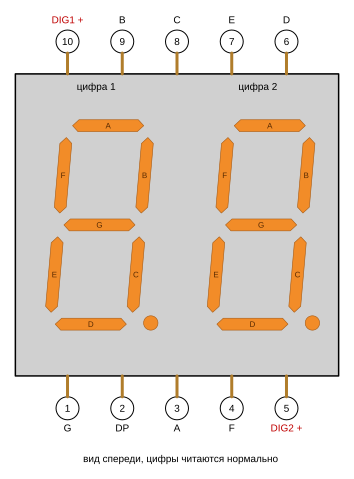

In [2]:
K = 0.6                      # 1 мм корпуса = 0.6 единицы рисунка
W, H = 15.0 * K, 14.0 * K
TILT = math.tan(math.radians(5))


def digit_segments(x0, y0, w, h, t):
    """Полигоны семи сегментов цифры; (x0, y0) — левый нижний угол."""
    hh = h / 2

    def hseg(y):
        return [(x0 + t, y), (x0 + t * 1.5, y + t / 2), (x0 + w - t * 1.5, y + t / 2),
                (x0 + w - t, y), (x0 + w - t * 1.5, y - t / 2), (x0 + t * 1.5, y - t / 2)]

    def vseg(x, ya, yb):
        return [(x, ya + t), (x + t / 2, ya + t * 1.5), (x + t / 2, yb - t * 1.5),
                (x, yb - t), (x - t / 2, yb - t * 1.5), (x - t / 2, ya + t * 1.5)]

    xl, xr = x0 + t / 2 + 0.02, x0 + w - t / 2 - 0.02
    segs = {'A': hseg(y0 + h), 'G': hseg(y0 + hh), 'D': hseg(y0),
            'F': vseg(xl, y0 + hh, y0 + h), 'B': vseg(xr, y0 + hh, y0 + h),
            'E': vseg(xl, y0, y0 + hh), 'C': vseg(xr, y0, y0 + hh)}
    # наклон вправо на 5° относительно низа цифры
    return {k: [(px + (py - y0) * TILT, py) for px, py in v] for k, v in segs.items()}


class E20362Front(elm.Element):
    def __init__(self, show_func=True, fs=1, **kwargs):
        """show_func=False — без подписей назначения выводов; fs — масштаб текста (для монтажной схемы)."""
        super().__init__(**kwargs)
        s = self.segments
        s.append(SegmentPoly([(0, 0), (W, 0), (W, H), (0, H)], fill=FACE, color='black', lw=1.5))

        dh, dw, t = 9.2 * K, 4.4 * K, 0.55 * K
        y0 = (H - dh) / 2
        for i, cx in enumerate((W / 2 - 3.75 * K, W / 2 + 3.75 * K)):   # цифры через 7,5 мм
            x0 = cx - dw / 2 - 0.15
            for name, poly in digit_segments(x0, y0, dw, dh, t).items():
                s.append(SegmentPoly(poly, fill=ORANGE, color=ORANGE_EDGE, lw=0.6))
                px = sum(p[0] for p in poly) / len(poly)
                py = sum(p[1] for p in poly) / len(poly)
                s.append(SegmentText((px, py), name, fontsize=8 * min(fs, 1.5), color='#5a2a00',
                                     align=('center', 'center'), zorder=5))
            s.append(SegmentCircle((x0 + dw + 0.35, y0 + t * 0.1), 0.2,
                                   fill=ORANGE, color=ORANGE_EDGE, lw=0.6))
            s.append(SegmentText((cx, H - 0.35), f'цифра {i + 1}', fontsize=10 * fs,
                                 align=('center', 'center')))

        # выводы: снизу 1..5 слева направо, сверху 10..6 слева направо
        r = 0.32 * max(1.0, 0.8 * fs)
        for i in range(5):
            x = W / 2 + (i - 2) * 2.54 * K
            for pin, y, va, ty in ((i + 1, -0.9, 'top', -1.35), (10 - i, H + 0.9, 'bottom', H + 1.35)):
                edge = 0 if y < 0 else H
                s.append(Segment([(x, edge), (x, y + (r if y < 0 else -r))], color=PIN_COLOR, lw=3))
                s.append(SegmentCircle((x, y), r, fill='white', color='black', lw=1))
                s.append(SegmentText((x, y), str(pin), fontsize=10 * fs, align=('center', 'center')))
                func = PIN_FUNC[pin]
                if show_func:
                    s.append(SegmentText((x, ty), func, fontsize=10 * fs,
                                         color=PLUS if '+' in func else 'black', align=('center', va)))


with schemdraw.Drawing(show=False) as d:
    d += E20362Front()
    d += elm.Label().at((W / 2, -2.4)).label('вид спереди, цифры читаются нормально', fontsize=10)
save(d, 'E20362-front')

## E20362 — внутренняя схема (CODE I, общий анод)

Как в даташите: у каждой цифры 8 светодиодов с общим анодом (10 / 5), катоды одноимённых сегментов обеих цифр соединены и выведены на один вывод.

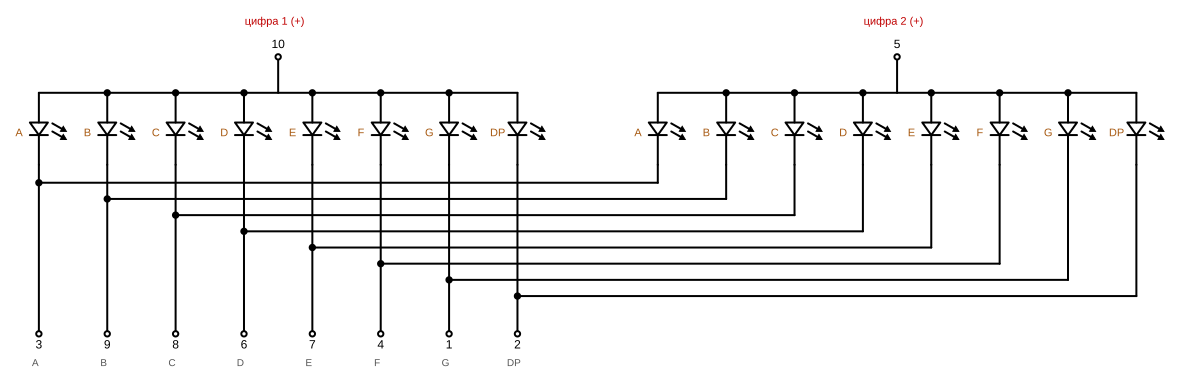

In [3]:
STEP, GAP, ROW = 1.9, 2.0, 0.45   # шаг светодиодов, зазор между цифрами, шаг перемычек

with schemdraw.Drawing(show=False) as d:
    d.config(unit=2)
    cathodes = {}
    for digit, (pin, xoff) in enumerate(((10, 0.0), (5, len(SEGMENTS) * STEP + GAP))):
        xs = [xoff + i * STEP for i in range(len(SEGMENTS))]
        mid = (xs[0] + xs[-1]) / 2
        d += elm.Line().at((xs[0], 0)).to((xs[-1], 0))             # шина анода
        d += elm.Line().at((mid, 0)).to((mid, 1.0))
        d += elm.Dot(open=True).at((mid, 1.0)).label(str(pin), loc='top')
        d += elm.Label().at((mid, 1.9)).label(f'цифра {digit + 1} (+)', fontsize=11, color=PLUS)
        for x, seg in zip(xs, SEGMENTS):
            if x not in (xs[0], xs[-1]):
                d += elm.Dot().at((x, 0))
            led = elm.LED().at((x, 0)).down()
            d += led
            d += elm.Label().at((x - 0.65, (led.start.y + led.end.y) / 2)).label(seg, fontsize=11, color=ORANGE_EDGE)
            cathodes[(digit, seg)] = (x, led.end.y)

    pin_y = min(y for _, y in cathodes.values()) - 0.5 - len(SEGMENTS) * ROW - 0.6
    for i, seg in enumerate(SEGMENTS):
        (x1, yb), (x2, _) = cathodes[(0, seg)], cathodes[(1, seg)]
        yj = yb - 0.5 - i * ROW
        d += elm.Line().at((x1, yb)).to((x1, pin_y))        # катод цифры 1 -> вывод
        d += elm.Dot().at((x1, yj))
        d += elm.Line().at((x1, yj)).to((x2, yj))            # перемычка к цифре 2
        d += elm.Line().at((x2, yj)).to((x2, yb))
        d += elm.Dot(open=True).at((x1, pin_y)).label(str(SEG_PINS[seg]), loc='bottom')
        d += elm.Label().at((x1, pin_y - 0.9)).label(seg, fontsize=10, color='#555555')
save(d, 'E20362-internal')

## Монтажная схема (как на макетке)

Плата горизонтально (USB слева), индикатор слева внизу — разводка индикатора как в led_clock_v2: ножки 10…6 ← D32, D33, D25, D26, D27 (провода буквой «Г»), ножки 1…5 ← D18, D19, D21, D22, D23.

Датчик температуры — над проводами индикатора: D14 → резистор 10 кОм → столбец D34; GND → свободный столбец правее EN; капля NTC — между столбцом D34 и этим столбцом. Серые полоски — столбцы макетки. Провода **не пересекаются** (число под ячейкой — 0).

пересечений проводов: 0


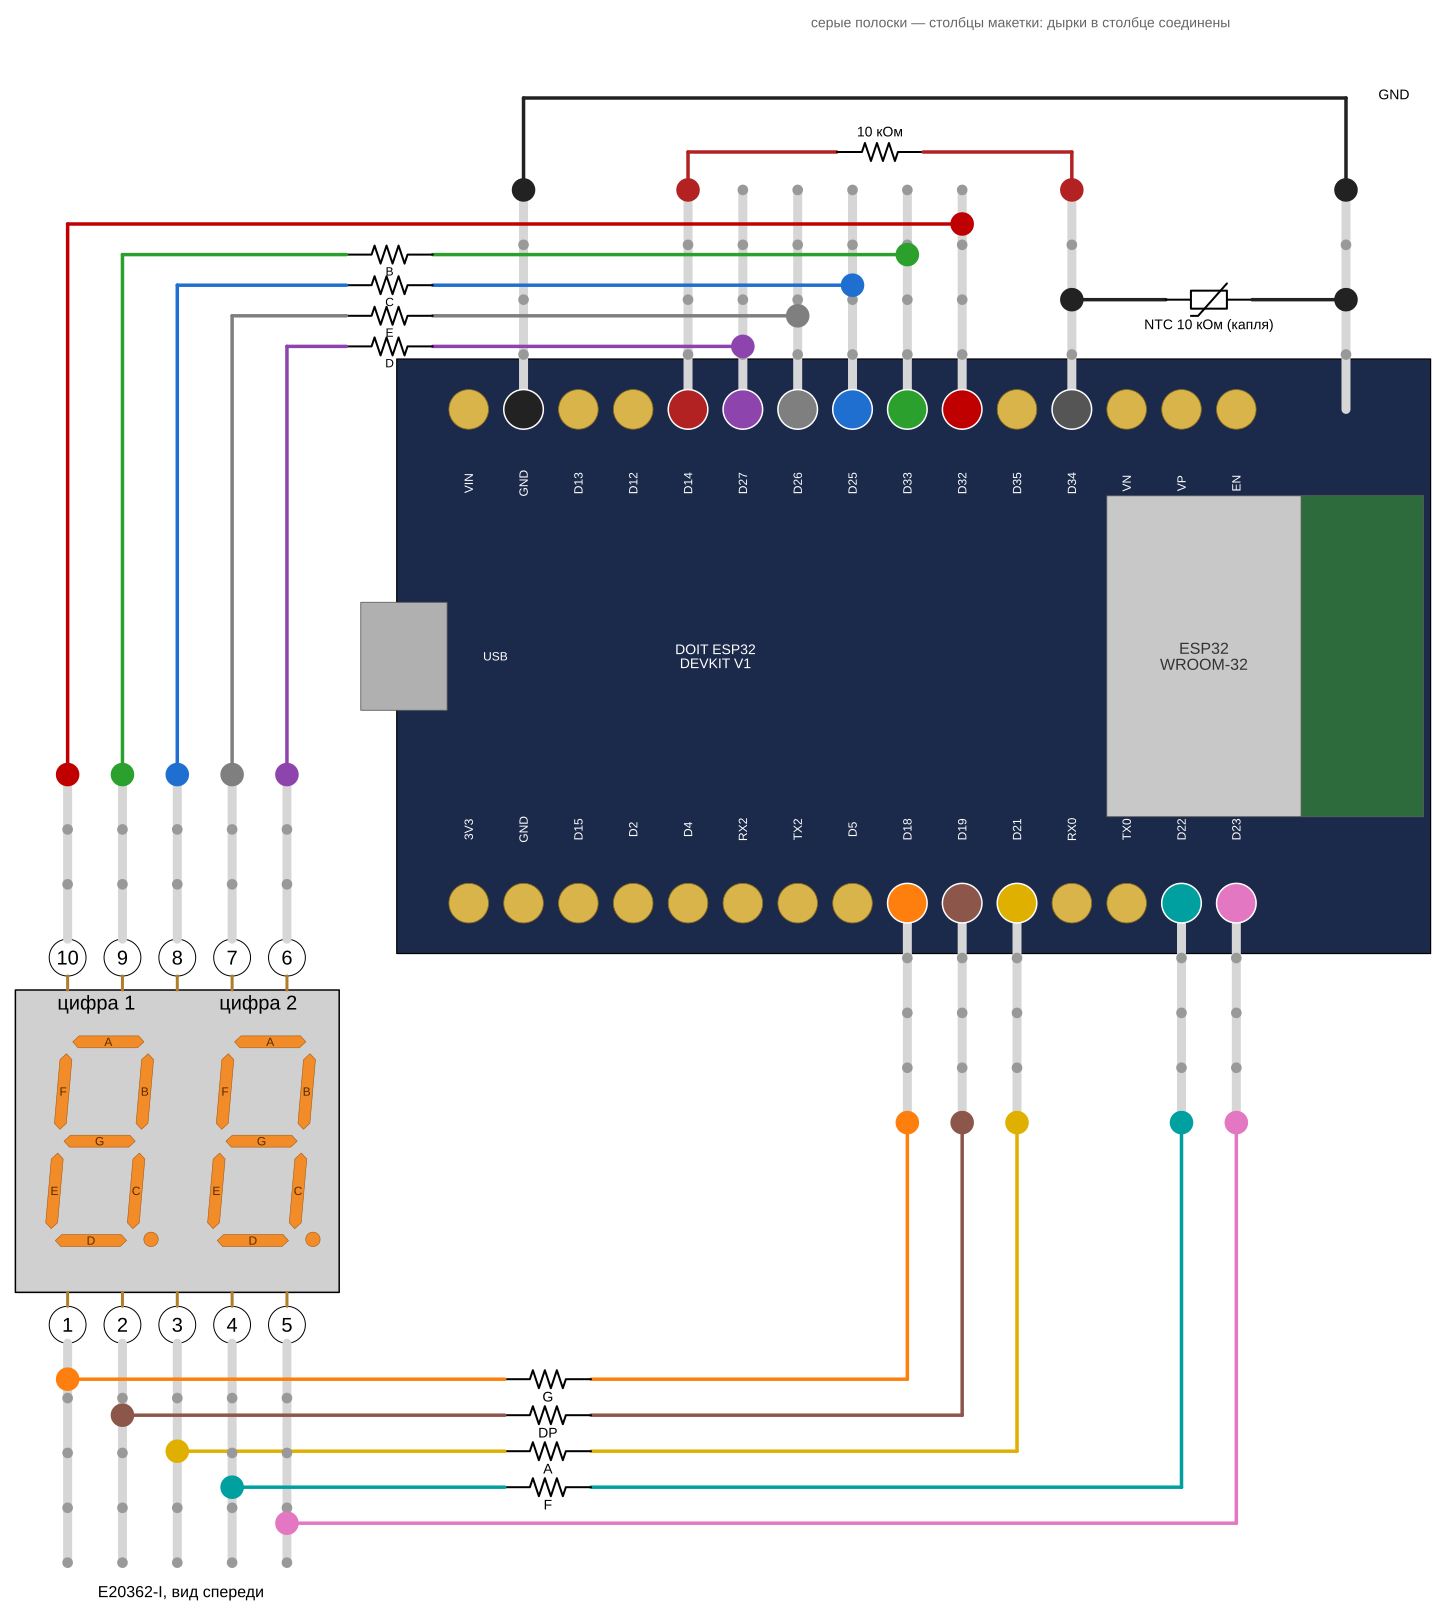

In [4]:
# Монтажная схема v2 — как на макетке: плата горизонтально (USB слева, антенна справа),
# индикатор слева внизу, цифры читаются нормально. Серые полоски — столбцы макетки
# (дырки в столбце соединены), провод втыкается в любую свободную дырку столбца.
# Верхние провода — буквой «Г»: из столбца над пином платы влево, затем вниз к столбцу
# над верхним рядом ножек индикатора. Нижние — из столбца под пином вниз, затем влево
# к столбцу под нижним рядом ножек. При таком порядке пинов провода не пересекаются.
# Масштаб: K = 0.6 единицы на мм, шаг 2,54 мм.
import itertools

P = 2.54 * K
FS = 2.0                                  # масштаб текста: схема крупная, в документе ужимается
PIN_R = 0.32 * max(1.0, 0.8 * FS)         # радиус кружка вывода индикатора (как в E20362Front)
ROW_GAP = 22.86 * K                       # расстояние между рядами выводов платы (0,9″)

# DOIT ESP32 DevKit V1 (30 выводов), вид сверху, USB слева. Ряды слева направо.
TOP_HDR = ['VIN', 'GND', 'D13', 'D12', 'D14', 'D27', 'D26', 'D25', 'D33', 'D32',
           'D35', 'D34', 'VN', 'VP', 'EN']
BOT_HDR = ['3V3', 'GND', 'D15', 'D2', 'D4', 'RX2', 'TX2', 'D5', 'D18', 'D19',
           'D21', 'RX0', 'TX0', 'D22', 'D23']

# Подключение v2: надпись на плате -> (сигнал, вывод индикатора, резистор?, цвет провода)
WIRES = {
    'D32': ('DIG1 +', 10, False, PLUS),
    'D33': ('B', 9, True, '#2ca02c'),
    'D25': ('C', 8, True, '#1f6fd1'),
    'D26': ('E', 7, True, '#7f7f7f'),
    'D27': ('D', 6, True, '#8e44ad'),
    'D18': ('G', 1, True, '#ff7f0e'),
    'D19': ('DP', 2, True, '#8c564b'),
    'D21': ('A', 3, True, '#e0b000'),
    'D22': ('F', 4, True, '#00a0a0'),
    'D23': ('DIG2 +', 5, False, '#e377c2'),
}
STRIP = '#d6d6d6'


class DevKitV1H(elm.Element):
    """DOIT ESP32 DevKit V1 горизонтально (USB слева). Якоря 'T_<надпись>' / 'B_<надпись>'."""
    def __init__(self, used=(), colors=None, **kwargs):
        super().__init__(**kwargs)
        colors = colors or {}
        s = self.segments
        right = 14 * P
        x0, x1, y0, y1 = -2.0, right + 5.4, -ROW_GAP - 1.4, 1.4
        s.append(SegmentPoly([(x0, y0), (x1, y0), (x1, y1), (x0, y1)],
                             fill='#1b2a4a', color='black', lw=1.2))                    # плата
        mx0, mx1, my0, my1 = right - 3.6, x1 - 0.2, -ROW_GAP + 2.4, -2.4
        s.append(SegmentPoly([(mx0, my0), (mx1, my0), (mx1, my1), (mx0, my1)],
                             fill='#c8c8c8', color='#555555', lw=0.8))                  # модуль WROOM-32
        s.append(SegmentPoly([(mx1 - 3.4, my0), (mx1, my0), (mx1, my1), (mx1 - 3.4, my1)],
                             fill='#2d6b3c', color='#555555', lw=0.8))                  # антенна
        s.append(SegmentText(((mx0 + mx1 - 3.4) / 2, -ROW_GAP / 2), 'ESP32\nWROOM-32',
                             fontsize=8 * FS, color='#333333', align=('center', 'center')))
        s.append(SegmentPoly([(x0 - 1.0, -ROW_GAP / 2 - 1.5), (x0 + 1.4, -ROW_GAP / 2 - 1.5),
                              (x0 + 1.4, -ROW_GAP / 2 + 1.5), (x0 - 1.0, -ROW_GAP / 2 + 1.5)],
                             fill='#b0b0b0', color='#555555', lw=0.8))                  # USB
        s.append(SegmentText((x0 + 2.4, -ROW_GAP / 2), 'USB', fontsize=6 * FS, color='white',
                             align=('left', 'center')))
        s.append(SegmentText((4.5 * P, -ROW_GAP / 2), 'DOIT ESP32\nDEVKIT V1', fontsize=7 * FS,
                             color='white', align=('center', 'center')))
        for side, names, y, ly, va in (('T', TOP_HDR, 0.0, -0.75, 'top'),
                                       ('B', BOT_HDR, -ROW_GAP, -ROW_GAP + 0.75, 'bottom')):
            for i, name in enumerate(names):
                x = i * P
                key = f'{side}_{name}'           # 'T_GND' и 'B_GND' — разные выводы
                on = key in used
                s.append(SegmentCircle((x, y), 0.55, fill=colors.get(key, '#d9b44a') if on else '#d9b44a',
                                       color='white' if on else '#8a6d1e', lw=1.5 if on else 0.8, zorder=4))
                s.append(SegmentText((x, ly - 1.3 if va == 'top' else ly + 1.3), name, fontsize=6 * FS,
                                     color='white', rotation=90, align=('center', 'center'), zorder=4))
                self.anchors[f'{side}_{name}'] = (x, y)


# ---------------------------------------------------------------- геометрия
hdr = {n: ((TOP_HDR.index(n) * P, 0.0) if n in TOP_HDR else (BOT_HDR.index(n) * P, -ROW_GAP))
       for n in WIRES}
TOP_W = [n for n in WIRES if n in TOP_HDR]            # к верхнему ряду ножек
BOT_W = [n for n in WIRES if n in BOT_HDR]            # к нижнему ряду ножек

disp_x0 = -3.6 - W                                    # индикатор левее платы
top_pin_y = -ROW_GAP - 1.0
disp_y0 = top_pin_y - (H + 0.9 + PIN_R)
bot_pin_y = disp_y0 - 0.9 - PIN_R
pin_xy = {}
for i in range(5):
    x = disp_x0 + W / 2 + (i - 2) * P
    pin_xy[10 - i] = (x, top_pin_y)                   # верхний ряд: 10..6
    pin_xy[i + 1] = (x, bot_pin_y)                    # нижний ряд: 1..5

HDR_STRIP = 4 * P                                     # столбец макетки у платы: 4 свободные дырки
IND_TOP_STRIP = 3 * P                                 # над верхним рядом ножек индикатора
IND_BOT_STRIP = 4 * P                                 # под нижним рядом ножек
LANE_TOP = 0.85      # верхние дорожки плотнее: над ними должен остаться зазор до верхних дырок
LANE_BOT = 1.0       #   (туда подключены провода датчика)
R_LEN = 2.4

# Верхние провода: дальше по ряду ножек (к 10) — выше дорожка
top_lane = {n: 1.75 + [6, 7, 8, 9, 10].index(WIRES[n][1]) * LANE_TOP for n in TOP_W}
# Нижние провода: дальше по ряду ножек (к 5) — глубже дорожка
bot_lane = {n: bot_pin_y - 1.0 - [1, 2, 3, 4, 5].index(WIRES[n][1]) * LANE_BOT for n in BOT_W}
TOP_RES_X = -3.4                                      # где на верхних дорожках стоят резисторы
BOT_RES_X = 1.0                                       # и на нижних


def route(name):
    """Провод: ломаная от дырки в столбце у платы до дырки в столбце у ножки индикатора."""
    (hx, hy), (px, py) = hdr[name], pin_xy[WIRES[name][1]]
    if name in TOP_W:
        ly = top_lane[name]
        return [(hx, ly), (px, ly), (px, py + IND_TOP_STRIP)]
    ly = bot_lane[name]
    return [(hx, hy - HDR_STRIP), (hx, ly), (px, ly)]


def crossings(paths):
    segs = [(wi, a, b) for wi, pts in enumerate(paths) for a, b in zip(pts, pts[1:])]
    n = 0
    for (i, a, b), (j, c, e) in itertools.combinations(segs, 2):
        if i == j:
            continue
        for (h0, h1), (v0, v1) in (((a, b), (c, e)), ((c, e), (a, b))):
            if h0[1] == h1[1] and v0[0] == v1[0]:
                y, x = h0[1], v0[0]
                if (min(h0[0], h1[0]) < x < max(h0[0], h1[0])
                        and min(v0[1], v1[1]) < y < max(v0[1], v1[1])):
                    n += 1
    return n


# ---- Датчик температуры: делитель GPIO14 -> 10 кОм -> GPIO34 -> NTC -> GND ----
# Всё выше дорожек индикатора: провода не пересекаются с ними.
NTC_PWR, NTC_ADC, NTC_GND = 'D14', 'D34', 'GND'
PWR_COLOR, GND_COLOR = '#b22222', '#222222'
x_pwr = TOP_HDR.index(NTC_PWR) * P
x_adc = TOP_HDR.index(NTC_ADC) * P
x_gnd = TOP_HDR.index(NTC_GND) * P
x_free = 16 * P                                   # свободный столбец макетки правее EN
y_strip_top = HDR_STRIP                           # верхняя дырка столбцов над платой
y_pwr = max(top_lane.values()) + 2.0              # провод питания делителя
y_gnd = y_pwr + 1.5                               # провод земли — ещё выше
y_ntc = 2 * P                                     # капля: дырки в середине столбцов
ntc_paths = [
    [(x_pwr, y_strip_top), (x_pwr, y_pwr), (x_adc, y_pwr), (x_adc, y_strip_top)],
    [(x_gnd, y_strip_top), (x_gnd, y_gnd), (x_free, y_gnd), (x_free, y_strip_top)],
    [(x_adc, y_ntc), (x_free, y_ntc)],
]
print('пересечений проводов:', crossings([route(n) for n in WIRES] + ntc_paths))


def strip(d, x, y_from, y_to):
    """Столбец макетки: серая полоска с дырками."""
    d.add(elm.Line(color=STRIP, lw=9).at((x, y_from)).to((x, y_to)))
    step = P if y_to > y_from else -P
    y = y_from + step
    while (y <= y_to + 1e-6) if step > 0 else (y >= y_to - 1e-6):
        d.add(elm.Dot(radius=0.12, color='#999999').at((x, y)))
        y += step


# ---------------------------------------------------------------- рисунок
ROUTE_W = 3.5
with schemdraw.Drawing(show=False) as d:
    d.config(unit=R_LEN)
    # столбцы макетки (под проводами)
    for n in WIRES:
        hx, hy = hdr[n]
        strip(d, hx, hy, hy + HDR_STRIP if n in TOP_W else hy - HDR_STRIP)
    for p, (px, py) in pin_xy.items():
        strip(d, px, py, py + IND_TOP_STRIP if p >= 6 else py - IND_BOT_STRIP)
    for x in (x_pwr, x_adc, x_gnd, x_free):          # столбцы делителя датчика
        strip(d, x, 0.0, HDR_STRIP)

    # .right(): иначе элемент повернётся по направлению последней нарисованной линии
    used = {('T_' if n in TOP_HDR else 'B_') + n: c for n, (_, _, _, c) in WIRES.items()}
    used.update({'T_' + NTC_PWR: PWR_COLOR, 'T_' + NTC_ADC: '#555555', 'T_' + NTC_GND: GND_COLOR})
    d += DevKitV1H(used=set(used), colors=used).right().at((0, 0))
    d += E20362Front(show_func=False, fs=FS).right().at((disp_x0, disp_y0))

    for n, (sig, pin, via_r, color) in WIRES.items():
        pts = route(n)
        for a, b in zip(pts, pts[1:]):
            rx = TOP_RES_X if n in TOP_W else BOT_RES_X
            if via_r and a[1] == b[1] and min(a[0], b[0]) < rx < max(a[0], b[0]):
                # горизонтальный участок идёт влево: провод -> резистор -> провод
                d.add(elm.Line(color=color, lw=ROUTE_W).at(a).to((rx + R_LEN, a[1])))
                d.add(elm.Resistor().at((rx + R_LEN, a[1])).to((rx, a[1]))
                      .label(sig, loc='bottom', fontsize=(6 if n in TOP_W else 7) * FS))
                d.add(elm.Line(color=color, lw=ROUTE_W).at((rx, a[1])).to(b))
            else:
                d.add(elm.Line(color=color, lw=ROUTE_W).at(a).to(b))
        d.add(elm.Dot(radius=0.3, color=color).at(pts[0]))      # штекер в дырке у платы
        d.add(elm.Dot(radius=0.3, color=color).at(pts[-1]))     # штекер в дырке у индикатора

    # Делитель датчика: D14 -> 10 кОм -> столбец D34; GND -> свободный столбец; капля между ними
    (p0, p1, p2, p3), (g0, g1, g2, g3), _ = ntc_paths
    r0 = ((p1[0] + p2[0]) / 2 - R_LEN / 2, y_pwr)
    d.add(elm.Line(color=PWR_COLOR, lw=ROUTE_W).at(p0).to(p1))
    d.add(elm.Line(color=PWR_COLOR, lw=ROUTE_W).at(p1).to(r0))
    d.add(elm.Resistor().at(r0).to((r0[0] + R_LEN, y_pwr)).label('10 кОм', loc='top', fontsize=7 * FS))
    d.add(elm.Line(color=PWR_COLOR, lw=ROUTE_W).at((r0[0] + R_LEN, y_pwr)).to(p2))
    d.add(elm.Line(color=PWR_COLOR, lw=ROUTE_W).at(p2).to(p3))
    for a, b in zip((g0, g1, g2), (g1, g2, g3)):
        d.add(elm.Line(color=GND_COLOR, lw=ROUTE_W).at(a).to(b))
    t0 = ((x_adc + x_free) / 2 - R_LEN / 2, y_ntc)
    d.add(elm.Line(color=GND_COLOR, lw=ROUTE_W).at((x_adc, y_ntc)).to(t0))
    d.add(elm.Thermistor().at(t0).to((t0[0] + R_LEN, y_ntc)).label('NTC 10 кОм (капля)', loc='bottom', fontsize=7 * FS))
    d.add(elm.Line(color=GND_COLOR, lw=ROUTE_W).at((t0[0] + R_LEN, y_ntc)).to((x_free, y_ntc)))
    for pt, c in ((p0, PWR_COLOR), (p3, PWR_COLOR), (g0, GND_COLOR), (g3, GND_COLOR),
                  ((x_adc, y_ntc), GND_COLOR), ((x_free, y_ntc), GND_COLOR)):
        d.add(elm.Dot(radius=0.3, color=c).at(pt))
    d += elm.Label().at((x_free + 0.8, y_gnd)).label('GND', loc='right', fontsize=7 * FS, halign='left')

    d += elm.Label().at((disp_x0 + W / 2, min(bot_lane.values()) - 2.0)).label(
        'E20362-I, вид спереди', fontsize=8 * FS)
    d += elm.Label().at((10 * P, y_gnd + 2.0)).label(
        'серые полоски — столбцы макетки: дырки в столбце соединены', fontsize=7 * FS, color='#666666')
save(d, 'layout')


## Подключение к ESP32 — принципиальная схема (этап 1)

То же подключение в принципиальном виде: каждая линия — пин ESP32 → резистор → вывод индикатора, аноды цифр — напрямую. У пинов — номер GPIO и надпись на плате DOIT DevKit V1, у индикатора — номер вывода и сигнал.

Должно совпадать с таблицей в [03-hardware.md](../03-hardware.md) и пинами по умолчанию в `led_clock_v2.ino`.

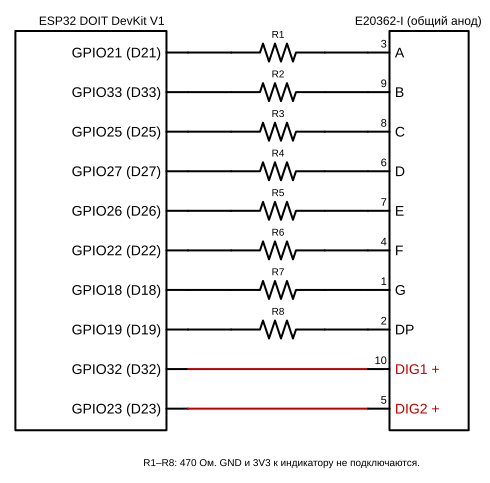

In [5]:
# Принципиальная схема подключения: ESP32 -> R1..R8 -> E20362, аноды напрямую.
# Данные — как в 03-hardware.md и config.example.h.
LINES = [  # (надпись на плате, GPIO, сигнал, вывод индикатора, через резистор)
    ('D21', 21, 'A', 3, True),
    ('D33', 33, 'B', 9, True),
    ('D25', 25, 'C', 8, True),
    ('D27', 27, 'D', 6, True),
    ('D26', 26, 'E', 7, True),
    ('D22', 22, 'F', 4, True),
    ('D18', 18, 'G', 1, True),
    ('D19', 19, 'DP', 2, True),
    ('D32', 32, 'DIG1 +', 10, False),
    ('D23', 23, 'DIG2 +', 5, False),
]
PITCH = 1.1                                   # шаг между линиями
BOX_H = (len(LINES) - 1) * PITCH + 1.2        # высота корпусов под 10 выводов
# Выводы elm.Ic перечисляются снизу вверх — список разворачиваем, чтобы A была сверху.
ORDER = list(reversed(list(enumerate(LINES))))

with schemdraw.Drawing(show=False) as d:
    d.config(unit=2.5)
    esp = elm.Ic(size=(4.2, BOX_H), pinspacing=PITCH, edgepadH=0.6, leadlen=0.6,
                 pins=[elm.IcPin(name=f'GPIO{gpio} ({lbl})', side='right', anchorname=f'p{i}')
                       for i, (lbl, gpio, *_) in ORDER]
                 ).label('ESP32 DOIT DevKit V1', loc='top', fontsize=12)
    d += esp

    r_idx, end_x = 0, None
    for i, (lbl, gpio, sig, pin, via_r) in enumerate(LINES):
        start = getattr(esp, f'p{i}')
        if via_r:
            r_idx += 1
            d += elm.Line().at(start).right(1.2)
            d += elm.Resistor().right(2.6).label(f'R{r_idx}', loc='top', fontsize=10)
            d += elm.Line().right(1.2)
        else:
            d += elm.Line(color=PLUS).at(start).right(5.0)
        end_x = d.here.x

    disp = elm.Ic(size=(2.2, BOX_H), pinspacing=PITCH, edgepadH=0.6, leadlen=0.6,
                  pins=[elm.IcPin(name=sig, pin=str(pin), side='left', anchorname=f'q{i}',
                                  color=PLUS if '+' in sig else None)
                        for i, (_, _, sig, pin, _) in ORDER]
                  ).label('E20362-I (общий анод)', loc='top', fontsize=12)
    d += disp.anchor('q0').at((end_x, esp.p0.y))   # вывод A индикатора — на конец линии A

    bottom = min(getattr(esp, f'p{i}').y for i in range(len(LINES))) - 1.6
    d += elm.Label().at(((esp.p0.x + end_x) / 2, bottom)).label(
        'R1–R8: 470 Ом.   GND и 3V3 к индикатору не подключаются.', fontsize=10)
save(d, 'connection')


## Делитель датчика температуры

GPIO14 даёт 3,3 В (HIGH), резистор 10 кОм и капля NTC делят напряжение, GPIO34 (вход АЦП) его измеряет. Чем теплее, тем меньше сопротивление капли и ниже напряжение: при 25 °C ≈ 1,65 В, при 0 °C ≈ 2,5 В, при 40 °C ≈ 1,1 В.

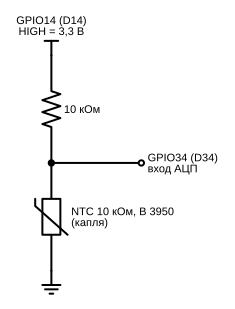

In [6]:
# Делитель датчика температуры: GPIO14 (HIGH = 3,3 В) -> 10 кОм -> GPIO34 (АЦП) -> NTC -> GND.
# Напряжение на GPIO34: U = 3,3 В * Rntc / (10 кОм + Rntc); при 25 °C (Rntc = 10 кОм) ≈ 1,65 В.
with schemdraw.Drawing(show=False) as d:
    d.config(unit=3)
    d += elm.Vdd().label('GPIO14 (D14)\nHIGH = 3,3 В', fontsize=11)
    d += elm.Resistor().down().label('10 кОм', loc='bottom', fontsize=11)
    d += elm.Dot()
    d.push()
    d += elm.Line().right(2.5)
    d += elm.Dot(open=True).label('GPIO34 (D34)\nвход АЦП', loc='right', fontsize=11)
    d.pop()
    d += elm.Thermistor().down().label('NTC 10 кОм, B 3950\n(капля)', loc='bottom', fontsize=11)
    d += elm.Ground()
save(d, 'ntc-divider')


## Подключение к ESP32 — схема проводов WireViz (для сравнения)

То же подключение в виде схемы жгутов: `W1`, `W2`, `W3` — группы проводов (W1: ESP32 → резисторы, W2: резисторы → индикатор, W3: аноды), цвета — рекомендация для макетки. Основная схема — принципиальная выше.

На этой схеме — только индикатор; датчик температуры — на монтажной схеме и схеме делителя выше.

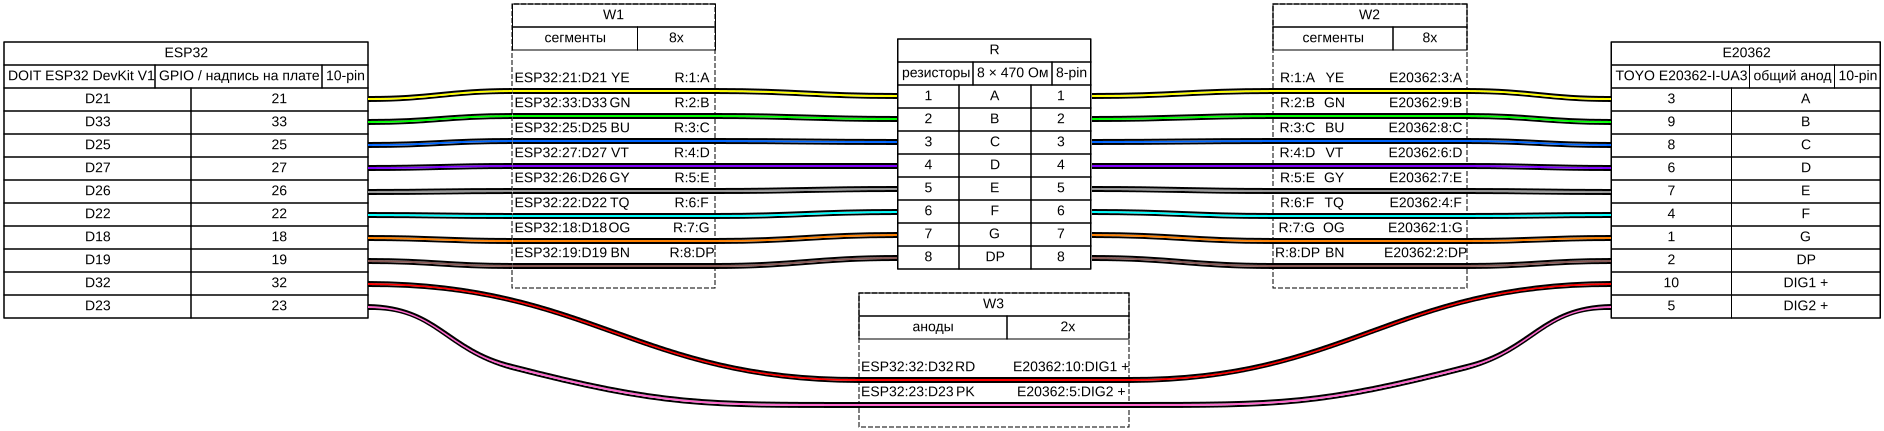

In [7]:
from wireviz.wireviz import parse

WIRING = '''
options:
  fontname: arial
  bgcolor: WH
  bgcolor_node: WH
  bgcolor_connector: WH
  bgcolor_cable: WH
  bgcolor_bundle: WH

connectors:
  ESP32:
    type: DOIT ESP32 DevKit V1
    subtype: GPIO / надпись на плате
    pins:      [21,  33,  25,  27,  26,  22,  18,  19,  32,  23]
    pinlabels: [D21, D33, D25, D27, D26, D22, D18, D19, D32, D23]
  R:
    type: резисторы
    subtype: 8 × 470 Ом
    pins:      [1, 2, 3, 4, 5, 6, 7, 8]
    pinlabels: [A, B, C, D, E, F, G, DP]
  E20362:
    type: TOYO E20362-I-UA3
    subtype: общий анод
    pins:      [3, 9, 8, 6, 7, 4, 1, 2, 10, 5]
    pinlabels: [A, B, C, D, E, F, G, DP, DIG1 +, DIG2 +]

cables:
  W1: {category: bundle, type: сегменты, colors: [YE, GN, BU, VT, GY, TQ, OG, BN], show_wirenumbers: false}
  W2: {category: bundle, type: сегменты, colors: [YE, GN, BU, VT, GY, TQ, OG, BN], show_wirenumbers: false}
  W3: {category: bundle, type: аноды,    colors: [RD, PK],                         show_wirenumbers: false}

connections:
  - [ESP32: [21, 33, 25, 27, 26, 22, 18, 19], W1: [1-8], R: [1-8]]
  - [R: [1-8], W2: [1-8], E20362: [3, 9, 8, 6, 7, 4, 1, 2]]
  - [ESP32: [32, 23], W3: [1-2], E20362: [10, 5]]
'''

parse(WIRING, output_formats=('svg',), output_dir=str(OUT), output_name='wiring')
display(SVG(filename=str(OUT / 'wiring.svg')))